# Predicting life expectancy from health, immunization and socioeconomic factors

This notebook uses the WHO Life Expectancy dataset to build and evaluate a linear regression model. The four parts follow the project roles: data exploration and cleaning, model building, evaluation, and result plots.


In [1]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Data").is_dir())
DATA_PATH = ROOT / "Data" / "Life Expectancy Data.csv"


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


## Part 1: Data exploration, pre-processing charts and cleaning (Execution lead)

The first function reads the CSV and cleans the column names. The raw file has extra spaces at the ends of names and double spaces inside some names, so both are fixed before any analysis. We then call it on the dataset path and define the target column once.


In [3]:
def load_and_clean(path):
    """Read the CSV and clean the column names."""
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
    return df


In [4]:
TARGET = "Life expectancy"

df = load_and_clean(DATA_PATH)
assert TARGET in df.columns # assert is a Python keyword used for debugging. It tests a condition, and if the condition is False, it raises an AssertionError.

print("Shape:", df.shape)


Shape: (2938, 22)


Next we inspect the data: its size, the first rows, column types, summary statistics, and how many values are missing in each column.

In [5]:
df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [7]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [8]:
df.isna().sum()


Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness 1-19 years                 34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

The `plot_eda` function draws the charts we need before dropping anything. It shows the target distribution, missing values, correlations between numeric columns, and how three important features relate to life expectancy.

In [9]:
def plot_eda(df):
    """Draw the main exploratory charts for the dataset."""
    plt.figure(figsize=(8, 5))
    plt.hist(df[TARGET].dropna(), bins=30)
    plt.title("Distribution of life expectancy")
    plt.xlabel("Life expectancy (years)")
    plt.ylabel("Number of rows")
    plt.tight_layout()
    plt.show()

    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    missing.plot(kind="bar")
    plt.title("Missing values per column")
    plt.xlabel("Column")
    plt.ylabel("Number of missing values")
    plt.tight_layout()
    plt.show()

    correlation = df.corr(numeric_only=True)
    plt.figure(figsize=(16, 12))
    sns.heatmap(correlation, cmap="coolwarm", center=0)
    plt.title("Correlation heatmap of numeric columns")
    plt.xlabel("Column")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()

    scatter_columns = ["Schooling", "Income composition of resources", "Adult Mortality"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, column in zip(axes, scatter_columns):
        ax.scatter(df[column], df[TARGET], alpha=0.4, s=10)
        ax.set_title(f"{column} vs life expectancy")
        ax.set_xlabel(column)
        ax.set_ylabel("Life expectancy (years)")
    plt.tight_layout()
    plt.show()


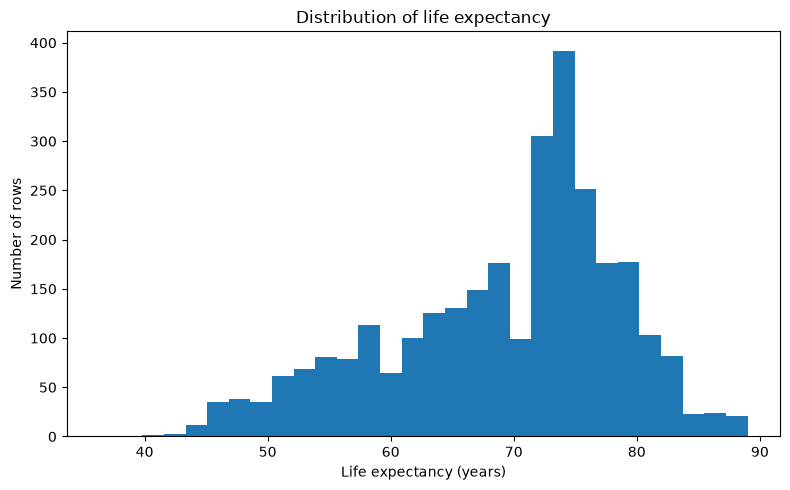

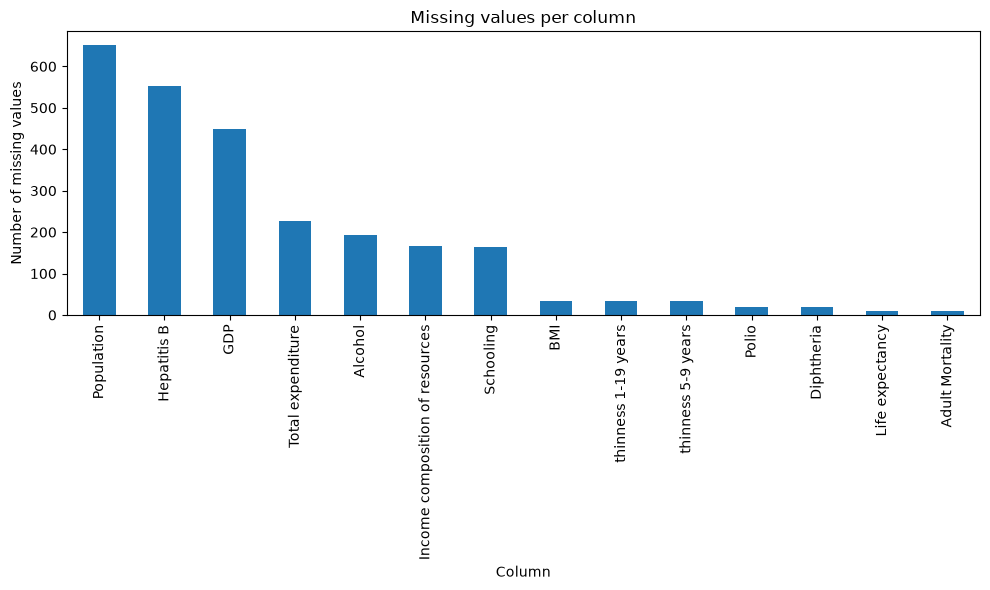

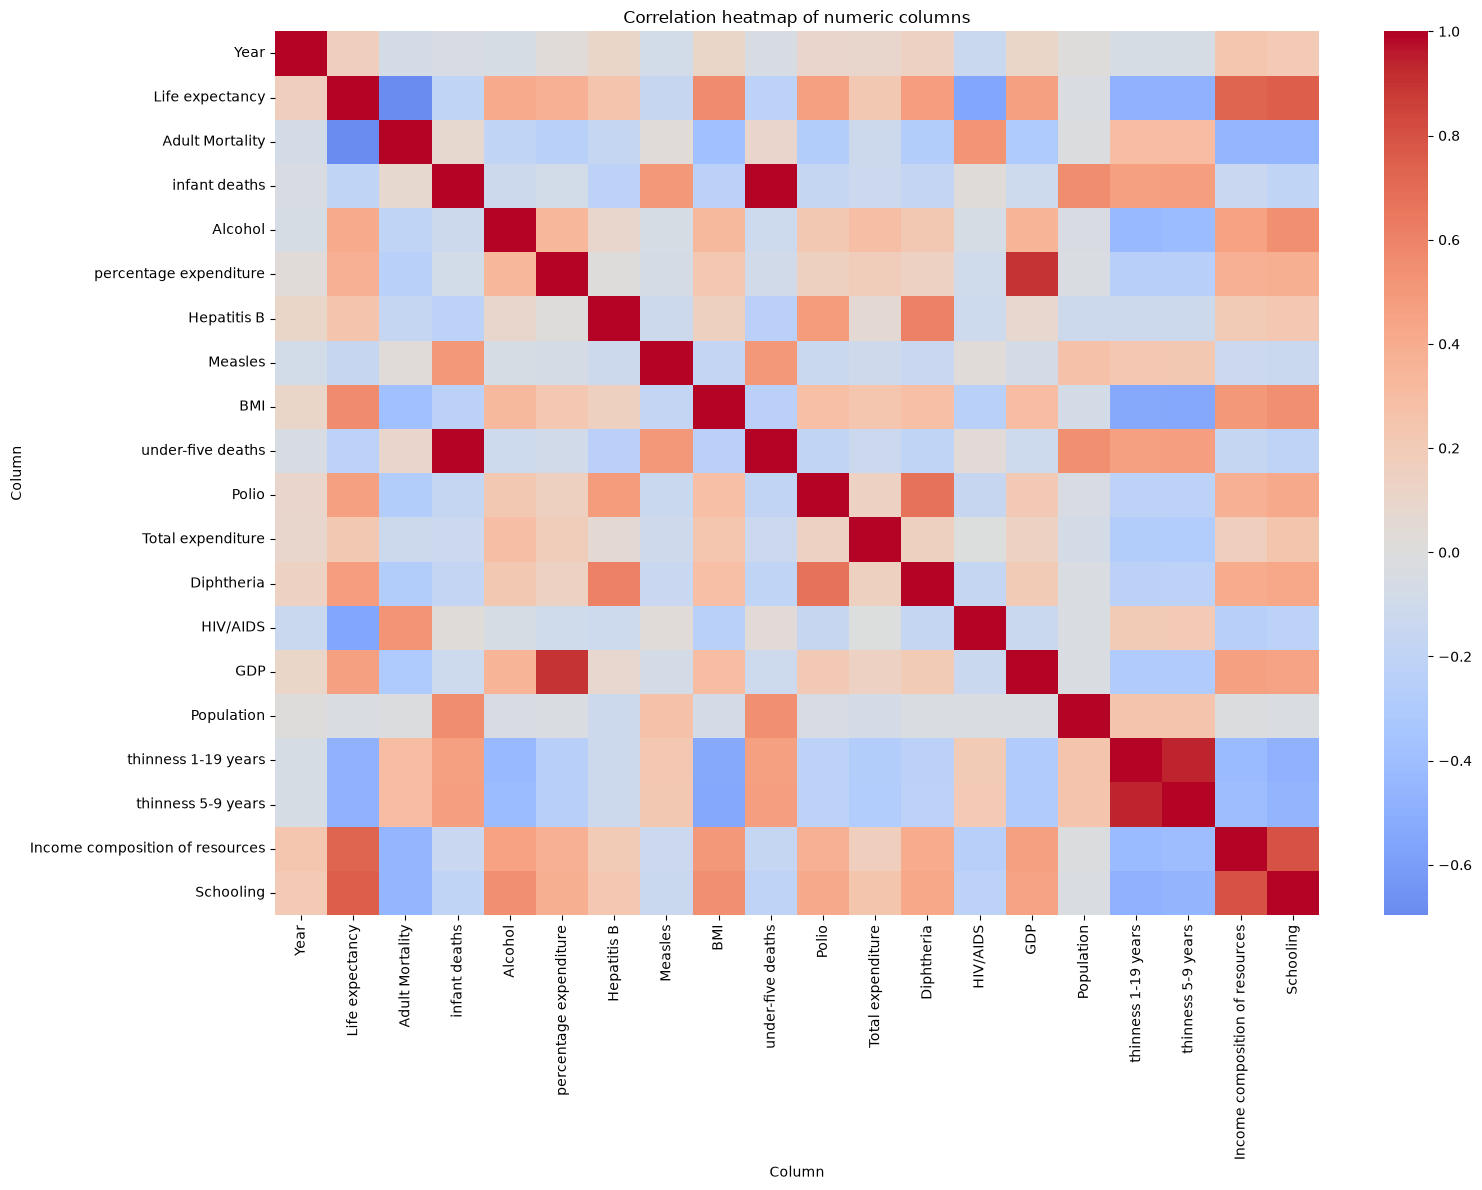

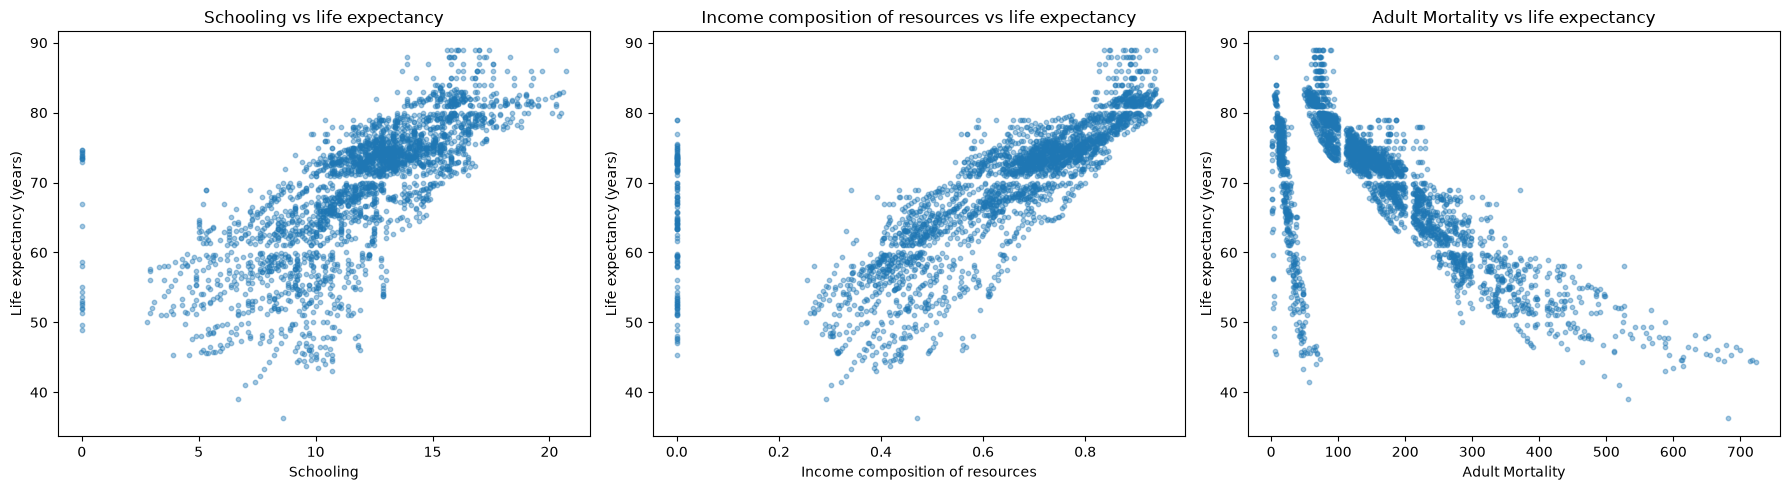

In [10]:
plot_eda(df)


We now remove columns and rows that would hurt the model or cannot be used. The reasons are kept in a dictionary so they can be printed and checked.

The redundant columns are kept in one list.

In [11]:
REDUNDANT_COLUMNS = ["infant deaths", "thinness 5-9 years", "percentage expenditure"]


`Country` is an identifier, rows without the target cannot be used, and the redundant columns duplicate information already in the dataset. The dictionary records one reason for each drop.

In [12]:
DROP_REASONS = {
    "Country": "Identifier with about 193 unique values; one-hot encoding it would add hundreds of columns.",
    "Rows with missing Life expectancy": "The target cannot be imputed, so these rows are removed.",
    "infant deaths": "Almost the same information as under-five deaths.",
    "thinness 5-9 years": "Almost the same information as thinness 1-19 years.",
    "percentage expenditure": "Almost the same information as GDP."
}

df = df.drop(columns=["Country"] + REDUNDANT_COLUMNS)
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

print("Dropped columns and rows:")
for name, reason in DROP_REASONS.items():
    print(f"- {name}: {reason}")
print("Shape after drops:", df.shape)


Dropped columns and rows:
- Country: Identifier with about 193 unique values; one-hot encoding it would add hundreds of columns.
- Rows with missing Life expectancy: The target cannot be imputed, so these rows are removed.
- infant deaths: Almost the same information as under-five deaths.
- thinness 5-9 years: Almost the same information as thinness 1-19 years.
- percentage expenditure: Almost the same information as GDP.
Shape after drops: (2928, 18)


The cleaned dataframe is split into features `X` and target `y`. `Country` is already gone, and `TARGET` is the life expectancy column.

In [13]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (2928, 17)
y shape: (2928,)


This part hands over `df`, `X` and `y`.

## Part 2: Splitting and model building (Documentation lead)

The `split_data` function separates the features and target into a training set and a test set. The test set is kept aside so the model is judged on data it did not see during training.

In [14]:
def split_data(X, y):
    """Split the data into training and test sets."""
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )
    return X_train, X_test, y_train, y_test

In [15]:
X_train, X_test, y_train, y_test = split_data(X, y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2342, 17)
X_test: (586, 17)
y_train: (2342,)
y_test: (586,)


The `build_preprocessor` function finds the numeric and categorical columns from the dataframe itself. Numeric missing values are filled with the median, and the categorical `Status` column is filled with the most frequent value and then one-hot encoded.

In [16]:
def build_preprocessor(X):
    """Build the preprocessing steps for numeric and categorical columns."""
    numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_transformer = SimpleImputer(strategy="median")
    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="if_binary",
                    sparse_output=False,
                ),
            ),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ],
        verbose_feature_names_out=False,
    )
    return preprocessor

In [17]:
preprocessor = build_preprocessor(X)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

The `train_model` function puts the preprocessor, a scaler, and a linear regression model into one pipeline. The pipeline is fitted only on the training data and returned for the later parts.

In [18]:
def train_model(preprocessor, X_train, y_train):
    """Fit and return the linear regression pipeline."""
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("scaler", StandardScaler()),
            ("regressor", LinearRegression()),
        ]
    )
    model.fit(X_train, y_train)
    return model


In [19]:
model = train_model(preprocessor, X_train, y_train)
model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Year','Status','Adult Mortality',...,'thinness 1-19 years', 'Income composition of resources','Schooling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_na

The imputer and the scaler live inside the pipeline on purpose. When the pipeline is fitted, they learn their values from the training data only, and the same learned values are then applied to the test data. This prevents information from the test set leaking into training.

This part hands over `X_train`, `X_test`, `y_train`, `y_test` and `model`.

# PART 3: VALIDATION, PREDICTION, EVALUATION AND INTERPRETATION (PPT LEAD)

##  Cross-validation

Five-fold cross-validation is performed on the training data. Each fold uses four parts for fitting and one part for validation. The test set remains untouched for the final evaluation.

In [20]:

def cross_validate_model(model, X_train, y_train):
    """Perform 5-fold cross-validation and return R² scores."""

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring="r2"
    )

    print("R² Scores for each fold:")
    for i, score in enumerate(cv_scores, start=1):
        print(f"Fold {i}: {score:.4f}")

    print(f"\nMean R² Score: {cv_scores.mean():.4f}")
    print(f"Standard Deviation: {cv_scores.std():.4f}")

    return cv_scores


# Execute cross-validation
cv_scores = cross_validate_model(model, X_train, y_train)


R² Scores for each fold:
Fold 1: 0.7996
Fold 2: 0.7989
Fold 3: 0.8145
Fold 4: 0.7936
Fold 5: 0.8265

Mean R² Score: 0.8066
Standard Deviation: 0.0121


Now the fitted model predicts life expectancy for both the test set and the training set. Both sets of predictions are kept because the next part plots them side by side.

In [21]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

print("Test predictions:", y_pred.shape)
print("Training predictions:", y_train_pred.shape)


Test predictions: (586,)
Training predictions: (2342,)


##  Test-set prediction and evaluation

The fitted pipeline predicts the held-out test set. MAE, MSE, RMSE and R2 are calculated from these predictions. The comparison table displays the first ten test observations.

In [22]:

def evaluate_model(model, X_test, y_test):
    """
    Generate test predictions and calculate regression metrics.
    """

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Display results
    print("Model Evaluation Results")
    print("-------------------------")
    print(f"Number of predictions: {len(y_pred)}")
    print(f"MAE: {mae:.4f}")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R² Score: {r2:.4f}")

    return y_pred, {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Evaluate the trained model
y_pred, evaluation_results = evaluate_model(
    model, X_test, y_test
)


Model Evaluation Results
-------------------------
Number of predictions: 586
MAE: 3.0163
MSE: 16.4700
RMSE: 4.0583
R² Score: 0.8096


##  Actual vs Predicted analysis

Points close to the diagonal line represent predictions close to the actual values. This plot is a visual check of test-set performance.

In [23]:

# Create a comparison of actual and predicted values

comparison_df = pd.DataFrame({
    "Actual Life Expectancy": y_test.values,
    "Predicted Life Expectancy": y_pred
})

comparison_df["Prediction Error"] = (
    comparison_df["Actual Life Expectancy"]
    - comparison_df["Predicted Life Expectancy"]
)

# Display the first 10 predictions
comparison_df.head(10)


,Actual Life Expectancy,Predicted Life Expectancy,Prediction Error
0,56.5,54.838307,1.661693
1,73.0,69.093137,3.906863
2,82.5,80.305777,2.194223
3,75.6,77.394298,-1.794298
4,53.0,57.490558,-4.490558
5,65.2,67.299239,-2.099239
6,72.4,73.077800,-0.677800
7,74.1,75.446664,-1.346664
8,77.0,76.292422,0.707578
9,67.8,72.494369,-4.694369


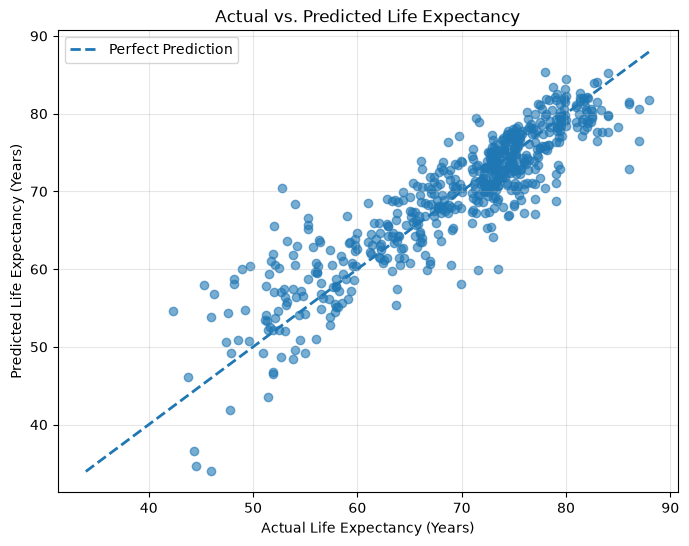

In [24]:

# Actual vs. Predicted Visualization

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Life Expectancy (Years)")
plt.ylabel("Predicted Life Expectancy (Years)")
plt.title("Actual vs. Predicted Life Expectancy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


##  Model Coefficients Analysis

The coefficients are extracted after preprocessing. Because the pipeline standardizes the transformed features, coefficient magnitudes describe the model's change in predicted years for a one-standard-deviation change in a transformed feature, holding the other features fixed. These are associations in the fitted model, not proof of causation.

In [25]:

def get_coefficients(model):
    """
    Extract feature names and their corresponding
    Linear Regression coefficients.
    """

    feature_names = (
        model.named_steps["preprocessor"].get_feature_names_out()
    )

    coefficients = model.named_steps["regressor"].coef_

    coefficient_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": coefficients
    })

    coefficient_df["Absolute Coefficient"] = (
        coefficient_df["Coefficient"].abs()
    )

    coefficient_df = coefficient_df.sort_values(
        by="Absolute Coefficient",
        ascending=False
    ).reset_index(drop=True)

    return coefficient_df


# Extract and display coefficients
coefficient_df = get_coefficients(model)

print("Feature Coefficient Analysis")
display(coefficient_df)


Feature Coefficient Analysis


,Feature,Coefficient,Absolute Coefficient
0,Adult Mortality,-2.597647,2.597647
1,HIV/AIDS,-2.538721,2.538721
2,Schooling,2.199354,2.199354
3,Income composition of resources,1.218236,1.218236
4,Diphtheria,1.139625,1.139625
5,BMI,0.838936,0.838936
6,Polio,0.788332,0.788332
7,GDP,0.595436,0.595436
8,Status_Developing,-0.549003,0.549003
9,Hepatitis B,-0.476103,0.476103


In [26]:
# Top 5 Positive Factors
positive_factors = coefficient_df[
    coefficient_df["Coefficient"] > 0
].nlargest(5, "Coefficient")[["Feature", "Coefficient"]]

# Top 5 Negative Factors
negative_factors = coefficient_df[
    coefficient_df["Coefficient"] < 0
].nsmallest(5, "Coefficient")[["Feature", "Coefficient"]]

print("Top 5 Positive Factors")
display(positive_factors.reset_index(drop=True))

print("Top 5 Negative Factors")
display(negative_factors.reset_index(drop=True))

Top 5 Positive Factors


,Feature,Coefficient
0,Schooling,2.199354
1,Income composition of resources,1.218236
2,Diphtheria,1.139625
3,BMI,0.838936
4,Polio,0.788332


Top 5 Negative Factors


,Feature,Coefficient
0,Adult Mortality,-2.597647
1,HIV/AIDS,-2.538721
2,Status_Developing,-0.549003
3,Hepatitis B,-0.476103
4,Measles,-0.376324



##  Model Interpretation And Key Findings

Based on the coefficient analysis, the following features show the strongest relationships with predicted life expectancy:

**Top Positive Factors:**
- Schooling (+2.1994): Shows the strongest positive association with predicted life expectancy.
- Income composition of resources (+1.2182): Indicates a positive association.
- Diphtheria (+1.1396): Also shows a positive association.

**Top Negative Factors:**
- Adult Mortality (-2.5976): Shows the strongest negative association with predicted life expectancy.
- HIV/AIDS (-2.5387): Shows another strong negative association.
- Status_Developing (-0.5490): Has a negative coefficient in the fitted model.

These coefficients represent associations within the Linear Regression model and should not be interpreted as proof of causation.

### Interpretation of Prediction Error (RMSE)
The RMSE of 4.0583 indicates that the model's prediction errors have a typical magnitude of approximately 4.06 years of life expectancy.


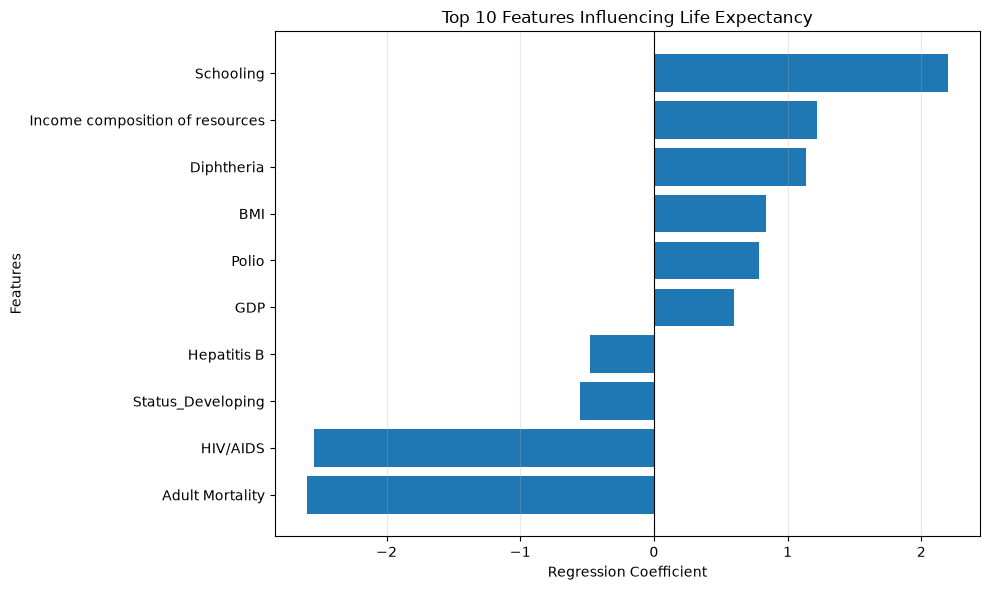

In [27]:

# Visualize the top 10 influential features

top_features = coefficient_df.head(10).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.xlabel("Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 10 Features Influencing Life Expectancy")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()



## Conclusion

The Linear Regression model achieved an R² score of 0.8096 on the test dataset, demonstrating its ability to explain a substantial proportion of the variation in life expectancy.

The 5-Fold Cross-Validation results showed a mean R² score of 0.8066 with a standard deviation of 0.0121, indicating consistent model performance across the validation folds.

The model recorded an MAE of 3.0163 years and an RMSE of 4.0583 years.

The coefficient analysis highlighted Adult Mortality and HIV/AIDS as the strongest negative factors, while Schooling showed the strongest positive association with predicted life expectancy.

Overall, the model provides reasonably good predictions, although further improvements may be possible through more advanced regression techniques and additional features.


This part hands over `cv_scores`, `y_pred`, `y_train_pred`, `evaluation_results`, `comparison_df`, `coefficient_df`, `positive_factors` and `negative_factors` for the final result visualizations and analysis.


## Part 4: Result plots, prediction demo and final run (Video lead)

The `plot_results` function draws the test and training predictions against the actual values, plus the test residuals. The `y = x` line marks perfect predictions, and the residual plot shows where the model over-predicts or under-predicts.

In [28]:
def plot_results(y_test, y_pred, y_train, y_train_pred):
    """Plot actual versus predicted values and the test residuals."""
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.5)
    line_min = min(y_test.min(), y_pred.min())
    line_max = max(y_test.max(), y_pred.max())
    plt.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--", label="y = x")
    plt.title("Test set: actual vs predicted life expectancy")
    plt.xlabel("Actual life expectancy (years)")
    plt.ylabel("Predicted life expectancy (years)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    residuals = y_test - y_pred
    plt.figure(figsize=(6, 5))
    plt.scatter(y_pred, residuals, alpha=0.5)
    plt.axhline(0, color="red", linestyle="--")
    plt.title("Test set: residuals vs predicted life expectancy")
    plt.xlabel("Predicted life expectancy (years)")
    plt.ylabel("Residual (actual - predicted, years)")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.scatter(y_train, y_train_pred, alpha=0.5)
    line_min = min(y_train.min(), y_train_pred.min())
    line_max = max(y_train.max(), y_train_pred.max())
    plt.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--", label="y = x")
    plt.title("Training set: actual vs predicted life expectancy")
    plt.xlabel("Actual life expectancy (years)")
    plt.ylabel("Predicted life expectancy (years)")
    plt.legend()
    plt.tight_layout()
    plt.show()


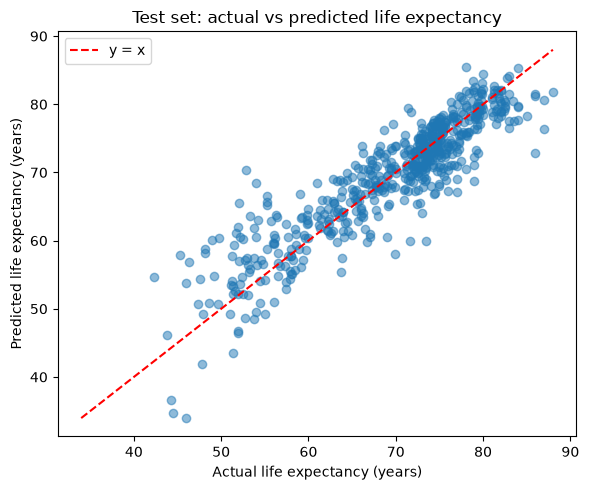

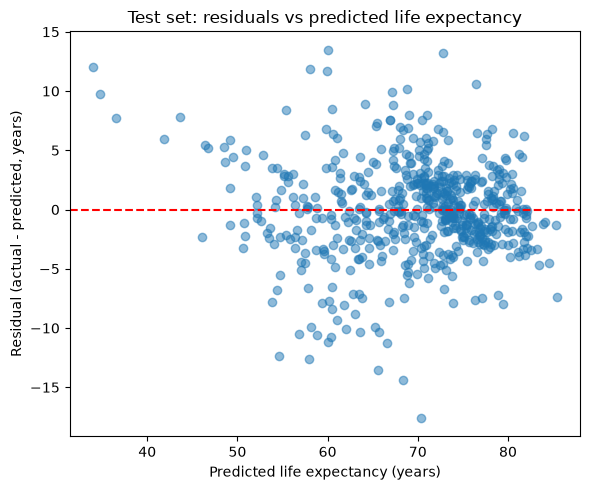

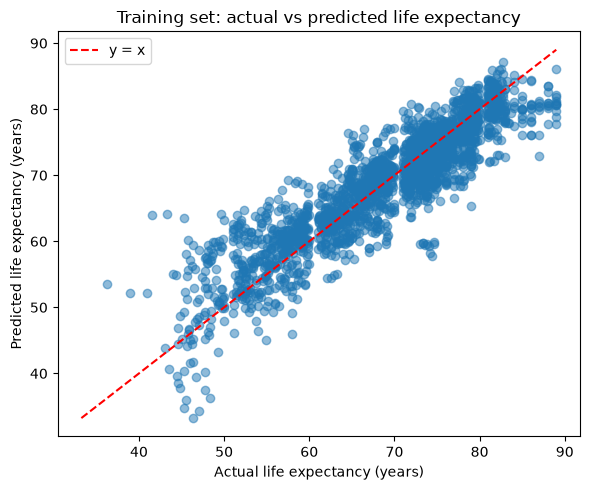

In [29]:
plot_results(y_test, y_pred, y_train, y_train_pred)


The `plot_coefficients` function turns the coefficient table into a horizontal bar chart. It shows the strongest positive and strongest negative coefficients so the direction of each effect is visible.

In [30]:
def plot_coefficients(coef_df, top_n=10):
    """Plot the strongest positive and negative coefficients."""
    top_positive = coef_df.head(top_n)
    top_negative = coef_df.tail(top_n)
    selected = pd.concat([top_negative, top_positive]).drop_duplicates(subset="Feature")
    selected = selected.sort_values("Coefficient")

    plt.figure(figsize=(10, 7))
    plt.barh(selected["Feature"], selected["Coefficient"])
    plt.axvline(0, color="red", linestyle="--")
    plt.title("Top positive and negative coefficients")
    plt.xlabel("Coefficient (standardized features)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


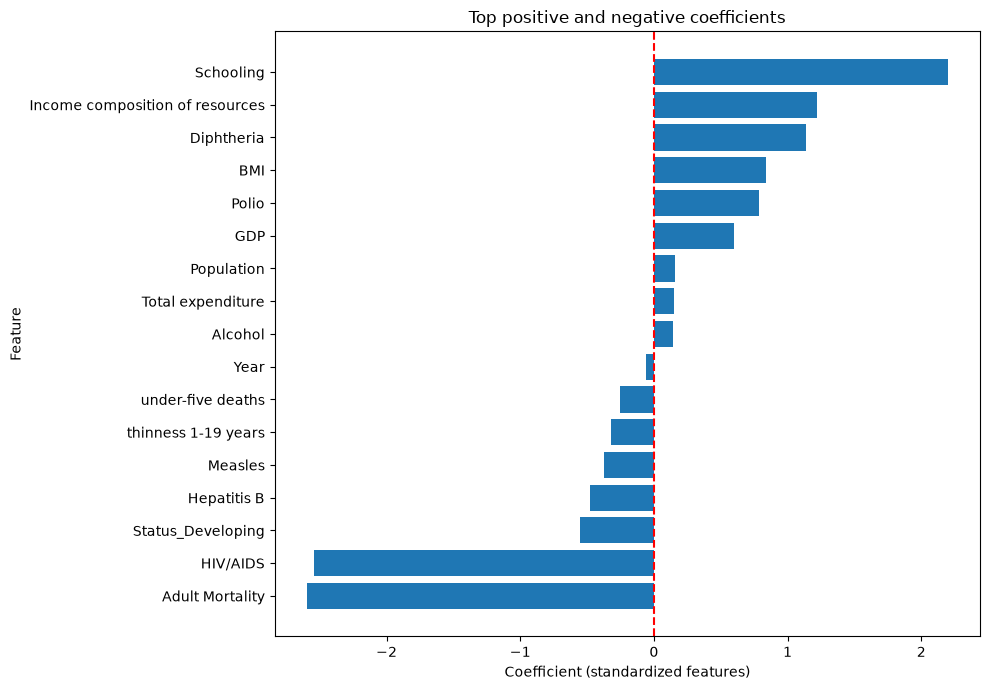

In [31]:
plot_coefficients(coefficient_df, top_n=10)


The `predict_new` function builds one hypothetical country-year from the training data and then applies a few chosen values. It returns the predicted life expectancy for that example.

In [32]:
def predict_new(model, X_train, overrides):
    """Predict life expectancy for one hypothetical country-year."""
    row = {}
    for column in X_train.columns:
        if pd.api.types.is_numeric_dtype(X_train[column]):
            row[column] = X_train[column].median()
        else:
            row[column] = X_train[column].mode().iloc[0]

    new_row = pd.DataFrame([row])
    for column, value in overrides.items():
        if column not in new_row.columns:
            raise KeyError(f"Unknown column in overrides: {column}")
        new_row[column] = value

    prediction = model.predict(new_row)[0]
    print(f"Predicted life expectancy: {prediction:.2f} years")
    return prediction


In [33]:
example_overrides = {
    "Year": 2015,
    "Status": "Developing",
    "Schooling": 12.0,
    "Adult Mortality": 150,
    "Income composition of resources": 0.6,
}

example_prediction = predict_new(model, X_train, example_overrides)


Predicted life expectancy: 70.59 years


The example values above are hypothetical (illustrative, not real country data).